In [47]:
from langgraph.graph import StateGraph, START, END
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import InMemoryVectorStore
from langchain_anthropic import ChatAnthropic
from pydantic import BaseModel, Field
from typing import List

#### Document Uploading, Splitting, Embeding, and storing.

In [48]:
# load pdf
loader = PyPDFLoader("../data/Afraz_Ahmad_CV.pdf")
pdf_doc = loader.load()

# split pdf data
split = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
pdf_split = split.split_documents(pdf_doc)

# embed
embeding = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")
vector_store = InMemoryVectorStore.from_documents(
    documents=pdf_doc,
    embedding=embeding
)


In [49]:
# llm
llm = ChatAnthropic(model="claude-sonnet-5-5")

### Creating State

In [50]:
class RagState(BaseModel):
    question: str = Field(description="User question")
    documents: List = [] # based on the question which similar documents we ahave found
    context: str = Field(description="Context data", default="") # context provided from the vector database
    answer: str = Field(description="Final Answer", default="")

### Creating Nodes

In [ ]:
# We have to create nodes for:
# 1. Similarty search
# 2. Context ""
# 3. prompt/generate answer

def retrieve_node(state:RagState) -> RagState:
    res_doc = vector_store.similarity_search(query=state.question)
    state.documents = res_doc
    return state

def context_node(state:RagState) -> RagState:
    context = "" 
    for doc in state.documents:
        context += doc.page_content + "\n"
        state.context = context
        return state

def generate_node(state:RagState) -> RagState:
    prompt = f"Answer the following question based on the context provided.\n\nContext:{state.context}\n\nQuestion: {state.question}\n\nAnswer:"
    answer = llm.invoke(prompt)
    state.answer = answer
    return state


### Creating Graph

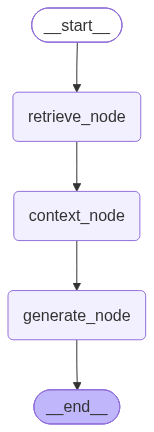

In [52]:
state_graph = StateGraph(RagState)

state_graph.add_node("retrieve_node", retrieve_node)
state_graph.add_node("context_node", context_node)
state_graph.add_node("generate_node", generate_node)

state_graph.add_edge(START, "retrieve_node")
state_graph.add_edge("retrieve_node", "context_node")
state_graph.add_edge("context_node", "generate_node")
state_graph.add_edge("generate_node", END)

state_graph = state_graph.compile()
state_graph

In [53]:
ans = state_graph.invoke({"question": "What is the name of Candidate?"})

In [56]:
# print(ans)
print(ans["answer"].content)

Afraz Ahmad
